In [1]:
import pandas as pd            
import numpy as np             
import matplotlib.pyplot as plt
import seaborn as sns          

In [2]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

In [4]:
df=pd.read_csv('../Data/polish_1year.csv')

In [5]:
print("Number of rows: ", df.shape[0])
print("Number of columns: ", df.shape[1])

Number of rows:  7027
Number of columns:  65


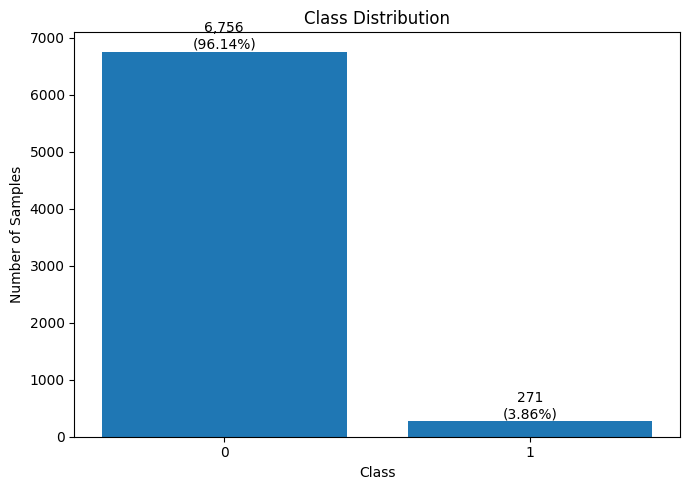

In [15]:


class_counts = df["class"].value_counts().sort_index()
class_percentages = df["class"].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(7, 5))

bars = plt.bar(
    class_counts.index.astype(str),
    class_counts.values
)

plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Class Distribution")

for bar, count, percentage in zip(
    bars,
    class_counts.values,
    class_percentages.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [6]:
missing = df.isna().sum()
print(missing[missing > 0])

net_profit_total_assets                                                                                             3
total_liabilities_total_assets                                                                                      3
working_capital_total_assets                                                                                        3
current_assets_short_term_liabilities                                                                              30
cash_securities_receivables_minus_short_term_liabilities_over_operating_expenses_minus_depreciation_times_365       8
retained_earnings_total_assets                                                                                      3
ebit_total_assets                                                                                                   3
book_value_equity_total_liabilities                                                                                25
sales_total_assets                                      

In [9]:
df.isna().sum().sum()

np.int64(5835)

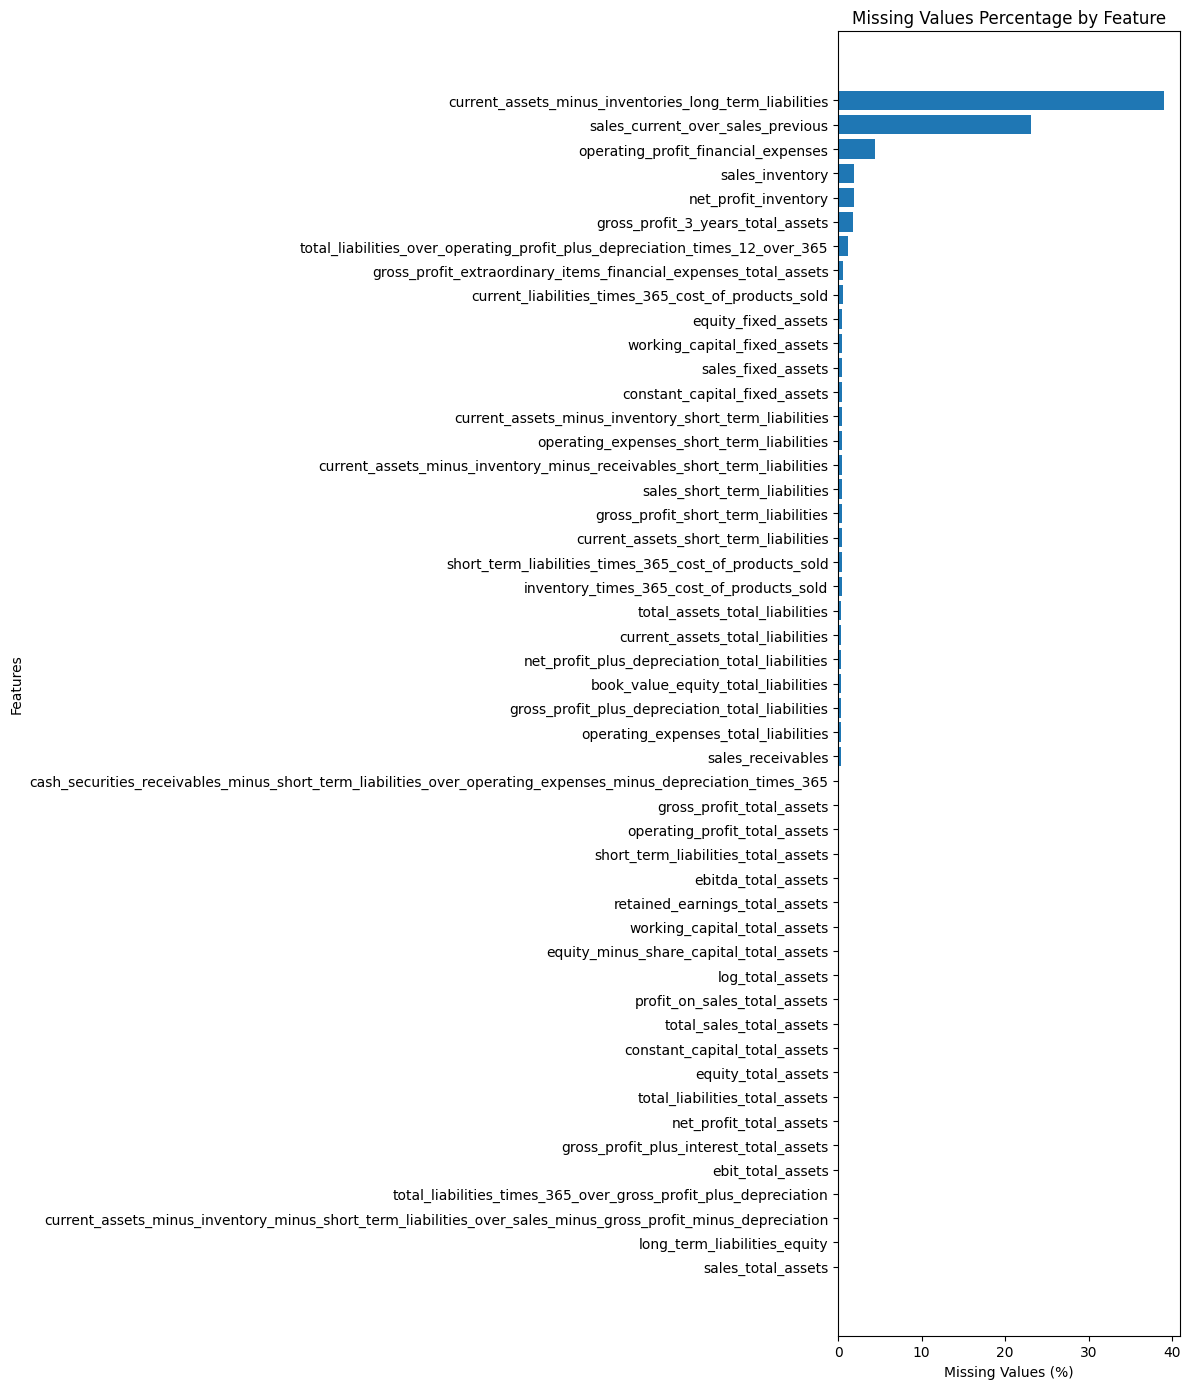

In [10]:
missing = df.isna().sum()
missing=missing[missing > 0]

# Calculate missing percentage
missing_percentage = (missing / len(df)) * 100

# Keep only features that have missing values
missing_percentage = missing_percentage[missing_percentage > 0]

# Sort from highest to lowest
missing_percentage = missing_percentage.sort_values(ascending=True)

# Plot
plt.figure(figsize=(12, 14))

plt.barh(
    missing_percentage.index,
    missing_percentage.values
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.title("Missing Values Percentage by Feature")

plt.tight_layout()
plt.show()

In [11]:
missing = df.isna().sum()

missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percentage": (missing / len(df)) * 100
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
]

missing_summary = missing_summary.sort_values(
    "missing_percentage",
    ascending=False
)

print(missing_summary)

                                                                                                               missing_count  \
current_assets_minus_inventories_long_term_liabilities                                                                  2740   
sales_current_over_sales_previous                                                                                       1622   
operating_profit_financial_expenses                                                                                      311   
sales_inventory                                                                                                          135   
net_profit_inventory                                                                                                     134   
gross_profit_3_years_total_assets                                                                                        124   
total_liabilities_over_operating_profit_plus_depreciation_times_12_over_365                             

In [16]:
feature = "current_assets_minus_inventories_long_term_liabilities"

result = df.groupby("class")[feature].apply(
    lambda x: x.isna().mean() * 100
)

print(result)

class
0    39.002368
1    38.745387
Name: current_assets_minus_inventories_long_term_liabilities, dtype: float64


In [17]:
features = [
    "current_assets_minus_inventories_long_term_liabilities",
    "sales_current_over_sales_previous"
]

for feature in features:
    print("=" * 80)
    print(feature)

    missing = df[feature].isna()

    print("\nMissing:")
    print("Count:", missing.sum())
    print("Percentage:", round(missing.mean() * 100, 2), "%")

    print("\nClass distribution when MISSING:")
    print(df.loc[missing, "class"].value_counts())
    print(df.loc[missing, "class"].value_counts(normalize=True) * 100)

    print("\nClass distribution when NOT MISSING:")
    print(df.loc[~missing, "class"].value_counts())
    print(df.loc[~missing, "class"].value_counts(normalize=True) * 100)

current_assets_minus_inventories_long_term_liabilities

Missing:
Count: 2740
Percentage: 38.99 %

Class distribution when MISSING:
class
0    2635
1     105
Name: count, dtype: int64
class
0    96.167883
1     3.832117
Name: proportion, dtype: float64

Class distribution when NOT MISSING:
class
0    4121
1     166
Name: count, dtype: int64
class
0    96.127828
1     3.872172
Name: proportion, dtype: float64
sales_current_over_sales_previous

Missing:
Count: 1622
Percentage: 23.08 %

Class distribution when MISSING:
class
0    1513
1     109
Name: count, dtype: int64
class
0    93.279901
1     6.720099
Name: proportion, dtype: float64

Class distribution when NOT MISSING:
class
0    5243
1     162
Name: count, dtype: int64
class
0    97.002775
1     2.997225
Name: proportion, dtype: float64


In [18]:
feature = "sales_current_over_sales_previous"

missing = df[feature].isna()

print("Missing rows:", missing.sum())

print(df.loc[missing, [
    "sales_current_over_sales_previous"
]].head(20))

Missing rows: 1622
     sales_current_over_sales_previous
4                                  NaN
7                                  NaN
20                                 NaN
21                                 NaN
22                                 NaN
28                                 NaN
46                                 NaN
53                                 NaN
59                                 NaN
60                                 NaN
67                                 NaN
70                                 NaN
75                                 NaN
76                                 NaN
78                                 NaN
82                                 NaN
86                                 NaN
98                                 NaN
103                                NaN
109                                NaN


In [19]:
print(df.columns.tolist())

['net_profit_total_assets', 'total_liabilities_total_assets', 'working_capital_total_assets', 'current_assets_short_term_liabilities', 'cash_securities_receivables_minus_short_term_liabilities_over_operating_expenses_minus_depreciation_times_365', 'retained_earnings_total_assets', 'ebit_total_assets', 'book_value_equity_total_liabilities', 'sales_total_assets', 'equity_total_assets', 'gross_profit_extraordinary_items_financial_expenses_total_assets', 'gross_profit_short_term_liabilities', 'gross_profit_plus_depreciation_sales', 'gross_profit_plus_interest_total_assets', 'total_liabilities_times_365_over_gross_profit_plus_depreciation', 'gross_profit_plus_depreciation_total_liabilities', 'total_assets_total_liabilities', 'gross_profit_total_assets', 'gross_profit_sales', 'inventory_times_365_sales', 'sales_current_over_sales_previous', 'operating_profit_total_assets', 'net_profit_sales', 'gross_profit_3_years_total_assets', 'equity_minus_share_capital_total_assets', 'net_profit_plus_dep

In [20]:
feature = "sales_current_over_sales_previous"

missing = df[feature].isna()

related_features = [
    "sales_total_assets",
    "gross_profit_sales",
    "inventory_times_365_sales",
    "receivables_times_365_sales",
    "sales_inventory",
    "sales_receivables",
    "short_term_liabilities_times_365_sales",
    "sales_short_term_liabilities",
    "sales_fixed_assets"
]

for col in related_features:
    print("=" * 70)
    print(col)

    print("Missing in ratio-missing rows:",
          df.loc[missing, col].isna().sum())

    print("Zero in ratio-missing rows:",
          (df.loc[missing, col] == 0).sum())

    print("Missing in ratio-present rows:",
          df.loc[~missing, col].isna().sum())

    print("Zero in ratio-present rows:",
          (df.loc[~missing, col] == 0).sum())

sales_total_assets
Missing in ratio-missing rows: 1
Zero in ratio-missing rows: 0
Missing in ratio-present rows: 0
Zero in ratio-present rows: 0
gross_profit_sales
Missing in ratio-missing rows: 0
Zero in ratio-missing rows: 3
Missing in ratio-present rows: 0
Zero in ratio-present rows: 2
inventory_times_365_sales
Missing in ratio-missing rows: 0
Zero in ratio-missing rows: 51
Missing in ratio-present rows: 0
Zero in ratio-present rows: 84
receivables_times_365_sales
Missing in ratio-missing rows: 0
Zero in ratio-missing rows: 10
Missing in ratio-present rows: 0
Zero in ratio-present rows: 12
sales_inventory
Missing in ratio-missing rows: 51
Zero in ratio-missing rows: 0
Missing in ratio-present rows: 84
Zero in ratio-present rows: 0
sales_receivables
Missing in ratio-missing rows: 10
Zero in ratio-missing rows: 0
Missing in ratio-present rows: 12
Zero in ratio-present rows: 0
short_term_liabilities_times_365_sales
Missing in ratio-missing rows: 0
Zero in ratio-missing rows: 15
Missing

In [21]:

print(df[feature].describe())

count     5405.000000
mean        10.367516
std        417.358298
min      -1325.000000
25%          1.024400
50%          1.137400
75%          1.287600
max      27900.000000
Name: sales_current_over_sales_previous, dtype: float64


In [22]:
feature = "current_assets_minus_inventories_long_term_liabilities"

correlation = df[feature].corr(df["class"])

print("Correlation with class:", correlation)

Correlation with class: -0.003910285171248453


In [23]:
df = df.drop(
    columns=["current_assets_minus_inventories_long_term_liabilities"]
)

In [24]:
features_group_1 = [
    "operating_profit_financial_expenses",
    "sales_inventory",
    "net_profit_inventory",
    "gross_profit_3_years_total_assets",
    "working_capital_fixed_assets",
    "sales_fixed_assets",
    "equity_fixed_assets",
    "constant_capital_fixed_assets",
    "sales_current_over_sales_previous",
    "total_liabilities_over_operating_profit_plus_depreciation_times_12_over_365"
]

results = []

for feature in features_group_1:
    missing_pct = df[feature].isna().mean() * 100

    missing_class_0 = df.loc[df["class"] == 0, feature].isna().mean() * 100
    missing_class_1 = df.loc[df["class"] == 1, feature].isna().mean() * 100

    correlation = df[feature].corr(df["class"])

    results.append({
        "feature": feature,
        "missing_%": missing_pct,
        "missing_class_0_%": missing_class_0,
        "missing_class_1_%": missing_class_1,
        "correlation_with_class": correlation
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="missing_%",
    ascending=False
)

print(results_df.to_string(index=False))

                                                                    feature  missing_%  missing_class_0_%  missing_class_1_%  correlation_with_class
                                          sales_current_over_sales_previous  23.082396          22.394908          40.221402               -0.003892
                                        operating_profit_financial_expenses   4.425786           2.827117          44.280443               -0.004650
                                                            sales_inventory   1.921161           1.791001           5.166052               -0.002482
                                                       net_profit_inventory   1.906930           1.776199           5.166052                0.002699
                                          gross_profit_3_years_total_assets   1.764622           1.835406           0.000000               -0.010807
total_liabilities_over_operating_profit_plus_depreciation_times_12_over_365   1.195389           1.243339 

In [25]:
features_group_2 = [
    "current_liabilities_times_365_cost_of_products_sold",
    "short_term_liabilities_times_365_cost_of_products_sold",
    "inventory_times_365_cost_of_products_sold",
    "operating_expenses_short_term_liabilities",
    "gross_profit_short_term_liabilities",
    "current_assets_short_term_liabilities",
    "sales_short_term_liabilities",
    "current_assets_minus_inventory_short_term_liabilities",
    "current_assets_minus_inventory_minus_receivables_short_term_liabilities",
    "current_assets_total_liabilities",
    "net_profit_plus_depreciation_total_liabilities",
    "gross_profit_plus_depreciation_total_liabilities",
    "total_assets_total_liabilities",
    "operating_expenses_total_liabilities",
    "book_value_equity_total_liabilities",
    "sales_receivables",
    "cash_securities_receivables_minus_short_term_liabilities_over_operating_expenses_minus_depreciation_times_365",
    "total_liabilities_times_365_over_gross_profit_plus_depreciation"
]

results = []

for feature in features_group_2:
    results.append({
        "feature": feature,
        "missing_%": df[feature].isna().mean() * 100,
        "missing_class_0_%": (
            df.loc[df["class"] == 0, feature].isna().mean() * 100
        ),
        "missing_class_1_%": (
            df.loc[df["class"] == 1, feature].isna().mean() * 100
        ),
        "correlation_with_class": df[feature].corr(df["class"])
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="missing_%",
    ascending=False
)

print(results_df.to_string(index=False))

                                                                                                      feature  missing_%  missing_class_0_%  missing_class_1_%  correlation_with_class
                                                          current_liabilities_times_365_cost_of_products_sold   0.540771           0.547661           0.369004                0.050432
                                                        current_assets_minus_inventory_short_term_liabilities   0.441156           0.444050           0.369004                0.005647
                                      current_assets_minus_inventory_minus_receivables_short_term_liabilities   0.426925           0.444050           0.000000                0.010320
                                                                    operating_expenses_short_term_liabilities   0.426925           0.444050           0.000000                0.013934
                                                                        current_asset

## Fill missing value with linear Regression

In [28]:
df=pd.read_csv('../Data/polish_1year.csv')
x21 = "sales_current_over_sales_previous"
x37 = "current_assets_minus_inventories_long_term_liabilities"

# =========================
# X21 Correlation
# =========================

corr_x21 = df.drop(columns=["class"]).corr(method="pearson")[x21].drop(x21)
corr_x21 = corr_x21.abs().sort_values(ascending=False)

print("Top correlations with X21:")
print(corr_x21.head(15))


# =========================
# X37 Correlation
# =========================

corr_x37 = df.drop(columns=["class"]).corr(method="pearson")[x37].drop(x37)
corr_x37 = corr_x37.abs().sort_values(ascending=False)

print("\nTop correlations with X37:")
print(corr_x37.head(15))

Top correlations with X21:
long_term_liabilities_equity                                                                                    0.049362
operating_expenses_short_term_liabilities                                                                       0.032145
sales_short_term_liabilities                                                                                    0.028314
current_assets_total_liabilities                                                                                0.021279
receivables_plus_inventory_turnover_days                                                                        0.012282
current_assets_minus_inventory_minus_short_term_liabilities_over_sales_minus_gross_profit_minus_depreciation    0.011631
working_capital_total_assets                                                                                    0.011006
short_term_liabilities_total_assets                                                                             0.010846
recei